# Annotation : conversions de formats, masques -> objets, accord entre annotateurs, pre-annotation

Ce notebook s'execute depuis la racine du depot. Il montre, sur de vraies donnees :
1. l'aller-retour VOC -> COCO -> Labelme -> Label Studio -> CVAT -> pivot sur NEU-DET, avec
   verification que rien n'est perdu a chaque etape ;
2. les masques de Magnetic Tile convertis en polygones (YOLO-seg) et en boites orientees (YOLO-OBB) ;
3. l'accord entre deux annotateurs (simules) ;
4. la pre-annotation et l'ordre de relecture par incertitude.

In [1]:
import time  # time : mesure la duree de chaque conversion
from pathlib import Path  # Path : represente un chemin de fichier, fonctionne sous Windows comme sous Linux

import matplotlib.pyplot as plt  # matplotlib : trace les figures (images annotees)
import numpy as np  # numpy : calcul sur des tableaux de nombres (ici surtout le tirage au hasard)
import pandas as pd  # pandas : tableaux de donnees (resumes affiches en texte)

# accord entre annotateurs : pour des boites (detection) et pour des classes d'image (classification)
from vtb.annotate.agreement import box_agreement, classification_agreement
from vtb.annotate.check import same_annotations  # compare deux jeux d'annotations et liste les differences
from vtb.annotate.draw import draw_annotation  # dessine boites et polygones sur une copie de l'image

# lecture et ecriture des annotations dans les formats connus (voc, coco, labelme, labelstudio, cvat, vtb...)
from vtb.annotate.formats import read_annotations, write_annotations

# mask_to_polygons : contours d'un masque ; read_mask_folder : lit un dossier de masques et en extrait des objets
from vtb.annotate.masks import mask_to_polygons, read_mask_folder

# export vers un outil d'annotation et tri des images par incertitude (relire d'abord les cas douteux)
from vtb.annotate.preannotate import detection_uncertainty, export_predictions, order_by_uncertainty

# format pivot de la toolbox : Box = boite, ImageAnnotation = tout ce qui est annote sur une image
from vtb.annotate.schema import Box, ImageAnnotation, class_names_of
from vtb.io.images import read_image  # lit une image en tableau numpy (couleur ou niveaux de gris)

OUT = Path("outputs/annotation/notebook")  # dossier des fichiers produits par ce notebook
ASSETS = Path("docs/assets/annotation")  # dossier des figures et journaux reutilises dans la documentation
OUT.mkdir(parents=True, exist_ok=True)  # cree le dossier (et ses parents) s'il n'existe pas ; pas d'erreur s'il existe
ASSETS.mkdir(parents=True, exist_ok=True)  # idem pour le dossier des figures
# NEU-DET : jeu de defauts d'acier ; images dans IMAGES, annotations Pascal VOC (un XML par image) dans ANNOTATIONS
NEU_IMAGES, NEU_XML = Path("data/raw/neu_det/IMAGES"), Path("data/raw/neu_det/ANNOTATIONS")

## 1. Lire NEU-DET (Pascal VOC) dans le format pivot

In [2]:
# lit les XML VOC et les convertit au format pivot (format interne commun a tous les formats) : une annotation par image
reference = read_annotations("voc", NEU_IMAGES, NEU_XML)
class_names = class_names_of(reference)  # liste triee des classes presentes ; l'ordre fixe le numero de chaque classe
# nombre de boites par classe : on aplatit toutes les boites de toutes les images, puis on compte chaque classe
counts = pd.Series([b.label for a in reference for b in a.boxes]).value_counts().sort_index()
print(len(reference), "images |", int(counts.sum()), "boites | classes :", class_names)  # resume du jeu
print(counts.to_string())  # detail : nombre de boites pour chaque classe

1770 images | 4126 boites | classes : ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']
crazing             678
inclusion          1001
patches             866
pitted_surface      423
rolled-in_scale     620
scratches           538


## 2. La chaine de conversions, verifiee a chaque etape

Chaque format est ecrit puis relu ; `same_annotations` compare au pivot de depart (tolerance
0,01 pixel, la precision de CVAT). Une liste vide = aucune perte.

In [3]:
chain = [  # etapes de la chaine : (format, fichier ou dossier de sortie)
    ("coco", OUT / "neu_det.coco.json"),  # COCO : un seul JSON pour tout le jeu
    ("labelme", OUT / "labelme"),  # Labelme : un JSON par image, dans un dossier
    ("labelstudio", OUT / "labelstudio_tasks.json"),  # Label Studio : un fichier de "taches" JSON
    ("cvat", OUT / "neu_det.cvat.xml"),  # CVAT : un seul XML
    ("vtb", OUT / "neu_det.vtb.json"),  # vtb : le format pivot de la toolbox, en JSON
]
current, rows = reference, []  # current = jeu de l'etape en cours (au depart : la reference) ; rows = lignes du bilan
for fmt, target in chain:  # pour chaque format de la chaine, dans l'ordre
    start = time.perf_counter()  # top chrono (horloge precise) pour mesurer la duree de l'etape
    # ecrit le jeu courant dans ce format ; images_dir et document_root servent a ecrire des chemins d'images valides
    write_annotations(fmt, current, target, class_names=class_names, images_dir=NEU_IMAGES, document_root=NEU_IMAGES)
    current = read_annotations(fmt, NEU_IMAGES, target, document_root=NEU_IMAGES)  # relit ce qui vient d'etre ecrit
    issues = same_annotations(reference, current, tol=1e-2)  # compare a la reference de depart (ecart tolere : 0,01 pixel)
    rows.append(  # ajoute une ligne au bilan
        {  # une ligne = un dict {nom de colonne: valeur}
            "format": fmt,  # format de l'etape
            "images": len(current),  # nombre d'images relues
            "boites": sum(len(a.boxes) for a in current),  # nombre total de boites relues
            "differences": len(issues),  # 0 = rien n'a ete perdu ni deforme
            "secondes": round(time.perf_counter() - start, 2),  # duree de l'etape (ecriture + relecture + controle)
        }
    )
table = pd.DataFrame(rows).to_string(index=False)  # bilan en tableau, mis en texte (sans numeros de ligne)
(ASSETS / "conversion_chain.log").write_text(table + "\n", encoding="utf-8")  # garde le bilan pour la documentation
print(table)  # affiche le bilan

     format  images  boites  differences  secondes
       coco    1770    4126            0      0.13
    labelme    1770    4126            0      4.15
labelstudio    1770    4126            0      0.37
       cvat    1770    4126            0      0.11
        vtb    1770    4126            0      0.19


Toujours regarder quelques images apres une conversion : une image par classe, boites relues
depuis le dernier format de la chaine.

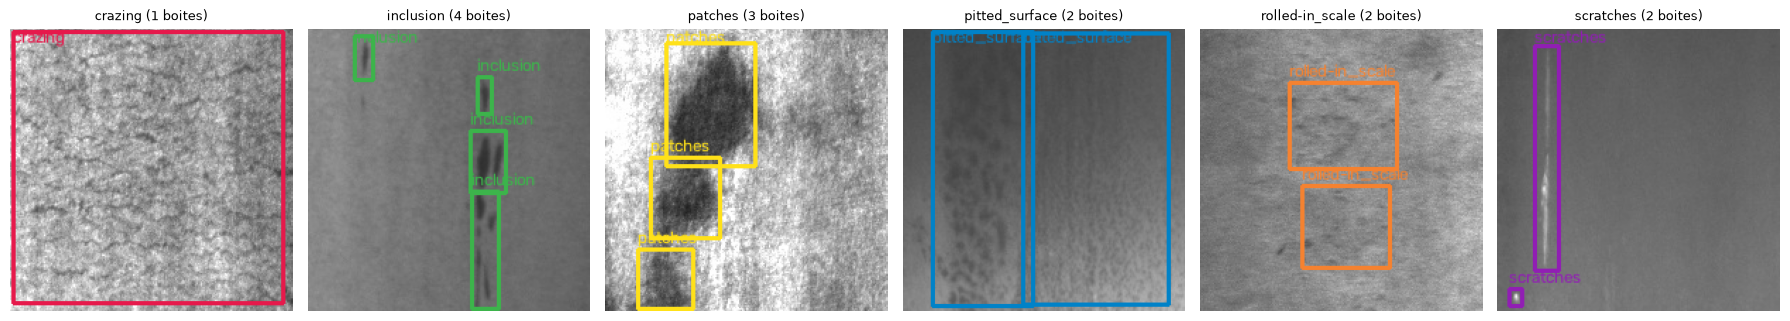

In [4]:
fig, axes = plt.subplots(1, 6, figsize=(18, 3.4))  # une figure de 1 ligne x 6 cases (une par classe), taille en pouces
by_name = {Path(a.image_path).name: a for a in current}  # annotations relues, indexees par nom de fichier
for ax, name in zip(axes, class_names):  # pour chaque case et chaque classe (zip les parcourt ensemble)
    ann = next(a for a in reference if a.boxes and a.boxes[0].label == name)  # 1re image dont la 1re boite est de cette classe
    back = by_name[Path(ann.image_path).name]  # la meme image, telle que relue en fin de chaine
    ax.imshow(draw_annotation(read_image(back.image_path), back, class_names))  # affiche l'image avec ses boites relues
    ax.set_title(f"{name} ({len(back.boxes)} boites)", fontsize=9)  # titre : classe et nombre de boites
    ax.axis("off")  # masque les axes gradues (inutiles pour une image)
plt.tight_layout()  # resserre les cases pour eviter les chevauchements
plt.savefig(ASSETS / "neu_det_boxes.png", dpi=90, bbox_inches="tight")  # enregistre la figure (dpi = resolution)
plt.show()  # affiche la figure dans le notebook

## 3. Masques -> polygones et boites orientees (Magnetic Tile)

Les masques sont a cote des images (`x.jpg` et `x.png`), d'ou `extensions=[".jpg"]`.
`epsilon` simplifie les contours : on compare le nombre de points et l'aire.

In [5]:
types = ["MT_Blowhole", "MT_Break", "MT_Crack", "MT_Fray", "MT_Uneven"]  # sous-dossiers du jeu = types de defauts
polygon_sets = {  # dict {type de defaut: annotations avec des polygones (contours des defauts)}
    t: read_mask_folder(  # lit les masques d'un type de defaut et en extrait les objets
        f"data/raw/magnetic_tile/{t}/Imgs",  # dossier des images
        f"data/raw/magnetic_tile/{t}/Imgs",  # dossier des masques : le meme, les masques sont a cote des images
        [t[3:].lower()],  # nom de la classe : "MT_Crack" -> "crack"
        kind="polygons",  # extrait le contour de chaque tache du masque (format YOLO-seg)
        extensions=[".jpg"],  # seules les .jpg sont des images (les .png sont les masques)
    )
    for t in types  # pour chaque type de defaut
}
rotated_sets = {  # dict {type de defaut: annotations avec des boites orientees}
    t: read_mask_folder(  # meme lecture que ci-dessus
        f"data/raw/magnetic_tile/{t}/Imgs",  # dossier des images
        f"data/raw/magnetic_tile/{t}/Imgs",  # dossier des masques (le meme)
        [t[3:].lower()],  # nom de la classe
        kind="rotated",  # boite orientee (OBB) : plus petit rectangle tourne qui entoure chaque tache
        extensions=[".jpg"],  # seules les .jpg sont des images
    )
    for t in types  # pour chaque type de defaut
}
summary = pd.DataFrame(  # tableau de synthese : une colonne par type de defaut (avant transposition)
    {  # dict {type: {nom de mesure: valeur}}
        t: {  # mesures pour ce type de defaut
            "images": len(polygon_sets[t]),  # nombre d'images
            "polygones": sum(len(a.polygons) for a in polygon_sets[t]),  # nombre total de polygones extraits
            "boites orientees": sum(len(a.rotated) for a in rotated_sets[t]),  # nombre total de boites orientees
        }
        for t in types  # pour chaque type de defaut
    }
).T  # .T transpose : une ligne par type de defaut, plus lisible
print(summary.to_string())  # affiche la synthese

             images  polygones  boites orientees
MT_Blowhole     115        118               118
MT_Break         85        117               117
MT_Crack         57         70                70
MT_Fray          32         38                38
MT_Uneven       103         99                99


In [6]:
crack = next(a for a in polygon_sets["MT_Crack"] if a.polygons)  # 1re image de fissure qui contient au moins un polygone
mask = read_image(crack.mask_path, color="gray")  # son masque en niveaux de gris (0 = fond, autre = defaut)
for eps in (0.0, 1.0, 2.0):  # pour trois niveaux de simplification du contour
    # epsilon = ecart maximal (pixels) autorise entre le contour simplifie et le vrai : plus grand = moins de points
    polys = mask_to_polygons(mask, ["crack"], epsilon=eps)
    print(f"epsilon {eps} : {sum(len(p.points) for p in polys)} points pour {len(polys)} polygone(s)")  # points obtenus

epsilon 0.0 : 138 points pour 1 polygone(s)
epsilon 1.0 : 41 points pour 1 polygone(s)
epsilon 2.0 : 10 points pour 1 polygone(s)


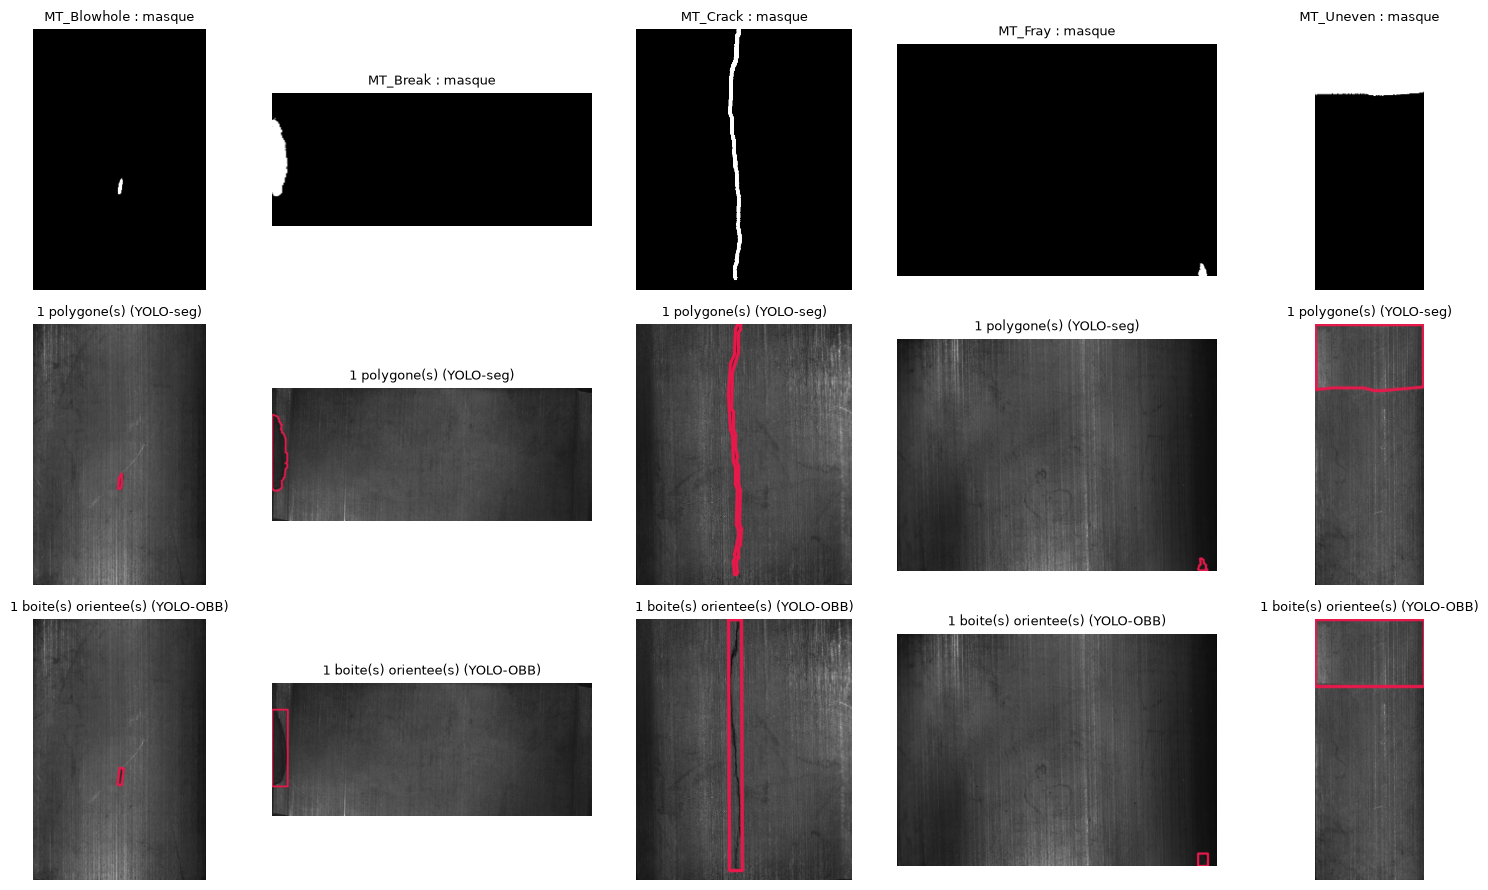

In [7]:
fig, axes = plt.subplots(3, 5, figsize=(16, 9))  # grille 3 lignes (masque, polygones, boites orientees) x 5 types
for col, t in enumerate(types):  # pour chaque type de defaut ; enumerate donne aussi son numero de colonne
    poly_ann = next(a for a in polygon_sets[t] if a.polygons)  # 1re image de ce type avec au moins un polygone
    rot_ann = next(a for a in rotated_sets[t] if a.image_path == poly_ann.image_path)  # la meme image, version boites orientees
    image = read_image(poly_ann.image_path)  # l'image elle-meme
    axes[0, col].imshow(read_image(poly_ann.mask_path, color="gray"), cmap="gray")  # 1re ligne : le masque brut
    axes[0, col].set_title(f"{t} : masque", fontsize=9)  # titre de la case
    axes[1, col].imshow(  # 2e ligne : les polygones dessines sur l'image
        draw_annotation(  # dessine les objets de l'annotation sur une copie de l'image
            image,  # l'image de fond
            # annotation reduite aux seuls polygones (largeur et hauteur de l'image sont obligatoires)
            ImageAnnotation(poly_ann.image_path, poly_ann.width, poly_ann.height, polygons=poly_ann.polygons),
            show_labels=False,  # sans le texte de la classe : la figure reste lisible
        )
    )
    axes[1, col].set_title(f"{len(poly_ann.polygons)} polygone(s) (YOLO-seg)", fontsize=9)  # titre : nombre de polygones
    axes[2, col].imshow(  # 3e ligne : les boites orientees dessinees sur l'image
        draw_annotation(  # meme dessin, avec les boites orientees
            image,  # l'image de fond
            # annotation reduite aux seules boites orientees
            ImageAnnotation(rot_ann.image_path, rot_ann.width, rot_ann.height, rotated=rot_ann.rotated),
            show_labels=False,  # sans le texte de la classe
        )
    )
    axes[2, col].set_title(f"{len(rot_ann.rotated)} boite(s) orientee(s) (YOLO-OBB)", fontsize=9)  # titre : nombre de boites
for ax in axes.ravel():  # pour chaque case de la grille (ravel met la grille 3 x 5 a plat)
    ax.axis("off")  # masque les axes gradues
plt.tight_layout()  # resserre les cases
plt.savefig(ASSETS / "magnetic_tile_masks_to_objects.png", dpi=80, bbox_inches="tight")  # enregistre la figure
plt.show()  # affiche la figure

## 4. Accord entre deux annotateurs (simule)

L'annotateur A est la verite de NEU-DET. L'annotateur B la reproduit avec les defauts
habituels : boites decalees de quelques pixels, 5 % de defauts oublies, 3 % de fausses boites,
4 % de classes differentes. L'accord mesure donne le plafond qu'un modele peut esperer.

In [8]:
rng = np.random.default_rng(0)  # generateur de hasard ; graine 0 = memes tirages a chaque execution
other = []  # annotations simulees de l'annotateur B
for ann in reference:  # pour chaque image de la reference (annotateur A)
    boxes = []  # boites que B dessine sur cette image
    for b in ann.boxes:  # pour chaque boite de A
        if rng.random() < 0.05:  # 5 % de chances : B oublie ce defaut
            continue  # passe a la boite suivante sans rien ajouter
        dx1, dy1, dx2, dy2 = rng.normal(0, 3, 4)  # 4 petits decalages au hasard (moyenne 0, ecart-type 3 pixels)
        # 4 % de chances : B se trompe de classe (classe tiree au hasard) ; sinon il garde celle de A
        label = class_names[rng.integers(len(class_names))] if rng.random() < 0.04 else b.label
        # boite decalee, bornee a l'image (max(0, ...) et min(largeur, ...) empechent de sortir du cadre)
        boxes.append(Box(label, max(0, b.x1 + dx1), max(0, b.y1 + dy1), min(ann.width, b.x2 + dx2), min(ann.height, b.y2 + dy2)))
    if rng.random() < 0.03:  # 3 % de chances : B ajoute une fausse boite
        boxes.append(Box(class_names[rng.integers(len(class_names))], 20, 20, 60, 60))  # carre de 40 px en haut a gauche
    other.append(ImageAnnotation(ann.image_path, ann.width, ann.height, boxes=boxes))  # annotation de B pour cette image
# compare B a A : deux boites "coincident" si leur IoU (surface commune / surface totale) atteint 0,5
agreement = box_agreement(reference, other, iou_threshold=0.5)
print({k: round(v, 3) if isinstance(v, float) else v for k, v in agreement.items()})  # mesures arrondies a 3 decimales
labels_a = [a.main_label() for a in reference]  # une classe par image pour A (classe la plus frequente de ses boites)
# B donne la meme classe que A, sauf dans 6 % des cas ou il en tire une au hasard
labels_b = [lab if rng.random() > 0.06 else class_names[rng.integers(len(class_names))] for lab in labels_a]
cls = classification_agreement(labels_a, labels_b)  # kappa de Cohen (accord corrige du hasard) et accord brut
print(f"classification : kappa {cls['kappa']:.3f} | accord brut {cls['raw_agreement']:.3f}")  # 1 = accord parfait

{'precision': 0.938, 'recall': 0.91, 'f1': 0.923, 'mean_iou': 0.844, 'label_agreement': 0.964, 'n_reference': 4126, 'n_other': 4002}
classification : kappa 0.942 | accord brut 0.951


## 5. Pre-annotation et ordre de relecture

Des predictions (ici simulees a partir de la verite, avec un score) sont exportees en taches
Label Studio (champ predictions) ; l'ordre de relecture met en tete les images ou le modele
hesite (score proche de 0,5).

In [9]:
predictions = [  # predictions simulees : les boites de la verite, chacune avec un score de confiance au hasard
    ImageAnnotation(  # une annotation par image
        a.image_path,  # chemin de l'image
        a.width,  # largeur en pixels
        a.height,  # hauteur en pixels
        # memes boites que la verite, avec un score tire entre 0,2 et 1 (6e champ de Box : la confiance du modele)
        boxes=[Box(b.label, b.x1, b.y1, b.x2, b.y2, float(rng.uniform(0.2, 1.0))) for b in a.boxes],
    )
    for a in reference[:200]  # sur les 200 premieres images seulement (rapide)
]
tasks = export_predictions(  # ecrit les predictions au format de l'outil choisi ; renvoie le chemin ecrit
    predictions,  # les predictions a exporter
    "labelstudio",  # outil de destination
    OUT / "preannotations_labelstudio.json",  # fichier de taches a importer dans Label Studio
    document_root=Path("data/raw"),  # les chemins d'images sont ecrits relativement a ce dossier
    min_score=0.25,  # les boites de score plus faible ne sont pas exportees
)
order = order_by_uncertainty(predictions)  # indices des images, de la plus incertaine a la plus sure
uncertainty = detection_uncertainty(predictions)  # incertitude de chaque image (score le plus proche de 0,5 = le plus douteux)
print("taches Label Studio :", tasks)  # chemin du fichier ecrit
print(  # affiche les 5 images a relire en premier
    pd.DataFrame(  # petit tableau : nom de l'image et incertitude
        {  # colonnes du tableau
            "image": [Path(predictions[i].image_path).name for i in order[:5]],  # nom des 5 images les plus incertaines
            "incertitude": [round(uncertainty[i], 3) for i in order[:5]],  # leur incertitude, arrondie
        }
    ).to_string(index=False)  # tableau mis en texte, sans numeros de ligne
)

taches Label Studio : outputs/annotation/notebook/preannotations_labelstudio.json
          image  incertitude
crazing_192.jpg        0.998
crazing_274.jpg        0.993
crazing_201.jpg        0.990
crazing_185.jpg        0.989
crazing_239.jpg        0.988
